# Classical ML models

Here I train the baseline, SVM and Random Forest on the same train / validation / test split as the deep learning notebook, then compare all models.

## Step 1 · Load the data
I load the split table and the resized images. Row i of the table is image i in the array. I also check the test images are exactly the ones the deep learning model was tested on, so the comparison is fair.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

df = pd.read_csv("data_split.csv")
images = np.load("images_224.npy")
print("table:", df.shape, "| images:", images.shape)
assert len(df) == len(images)       # row i of the table = image i

table: (5400, 6) | images: (5400, 224, 224)


In [2]:
def get_split(name):
    keep = (df.split == name).values
    return images[keep], df.label.values[keep]

x_train, y_train = get_split("train")
x_val, y_val = get_split("val")
x_test, y_test = get_split("test")

print("train / val / test:", len(y_train), len(y_val), len(y_test))
print("share of cancer:", y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

# the test images must be the same ones the deep learning model was tested on
dl_test = pd.read_csv("dl_predictions_test.csv")
assert (dl_test.path.values == df[df.split == "test"].path.values).all()
print("OK: same test images as the deep learning notebook")

train / val / test: 4320 540 540
share of cancer: 0.503 0.504 0.504
OK: same test images as the deep learning notebook


The split is the same as in the deep learning notebook (4320 train, 540 val, 540 test) and cancer is about 50% in each part. The test images are the same ones the deep learning model was tested on, so the comparison will be fair.

## Step 2 · Baseline
A baseline is a model that does no real learning. Mine ignores the image and always predicts the most common class in train. Every real model has to beat this, otherwise it learned nothing.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def scores(y, p, t=0.5):
    pred = (p >= t).astype(int)
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
        "roc_auc": roc_auc_score(y, p),
    }

# the baseline ignores the images and always predicts the most common class in train
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
p_base = baseline.predict_proba(np.zeros((len(y_test), 1)))[:, 1]

results = []
results.append({"model": "baseline (majority class)", **scores(y_test, p_base)})
pd.DataFrame(results).round(3)

,model,accuracy,precision,recall,f1,roc_auc
0,baseline (majority class),0.504,0.504,1.0,0.67,0.5


The baseline always predicts cancer, so its recall is 1.0 but accuracy is only 0.504 and ROC-AUC is 0.5, which is the same as guessing. This shows recall alone is not enough, and it is the line every real model has to beat.

## Step 3 · Turn each image into numbers
SVM and Random Forest need a table of numbers, not pictures. So for every image I calculate 20 numbers:
- 5 brightness numbers (mean, standard deviation, 10th / 50th / 90th percentile), using only the breast and not the black background
- 5 texture numbers (GLCM: contrast, dissimilarity, homogeneity, energy, correlation) that describe how smooth or rough the tissue pattern is
- 10 numbers from LBP, which counts small repeating patterns

After this, every image is one row in a table and the models are trained on it.

In [4]:
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

feature_names = (["mean", "std", "p10", "p50", "p90"]
                 + ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]
                 + [f"lbp_{i}" for i in range(10)])

def get_features(img):
    # 1) brightness numbers, using only the breast (skip the black background)
    tissue = img[img > 10]
    if len(tissue) < 10:
        tissue = img.ravel()
    bright = [tissue.mean(), tissue.std(), *np.percentile(tissue, [10, 50, 90])]

    # 2) texture numbers (GLCM): shades are reduced to 32 levels first
    small = (img // 8).astype(np.uint8)
    glcm = graycomatrix(small, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=32, symmetric=True, normed=True)
    props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]
    texture = [graycoprops(glcm, p).mean() for p in props]

    # 3) small repeating patterns (LBP), counted as a 10-bin histogram
    lbp = local_binary_pattern(img, 8, 1, method="uniform")
    hist, _ = np.histogram(lbp, bins=10, range=(0, 10), density=True)

    return np.nan_to_num(np.array(bright + texture + list(hist)))

print(len(feature_names), "features per image")
print(dict(zip(feature_names[:10], get_features(images[0]).round(2)[:10])))

20 features per image
{'mean': np.float64(90.53), 'std': np.float64(61.94), 'p10': np.float64(14.0), 'p50': np.float64(88.0), 'p90': np.float64(175.0), 'contrast': np.float64(0.66), 'dissimilarity': np.float64(0.22), 'homogeneity': np.float64(0.91), 'energy': np.float64(0.62), 'correlation': np.float64(0.99)}


### 3.2 Calculate for all images
This loops over all 5400 images and saves the table, so I don't have to calculate it again.

In [5]:
from tqdm import tqdm

X = np.array([get_features(img) for img in tqdm(images)])
np.save("features.npy", X)
print("feature table:", X.shape)       # one row per image, one column per feature

100%|██████████| 5400/5400 [01:03<00:00, 85.07it/s] 

feature table: (5400, 20)


### 3.3 Split the table and look at it
I split the feature table with the same train / val / test rows as before. Then I compare the average of each feature for benign (0) and cancer (1) in train.

In [6]:
X_train = X[(df.split == "train").values]
X_val = X[(df.split == "val").values]
X_test = X[(df.split == "test").values]

table = pd.DataFrame(X_train, columns=feature_names)
table["label"] = y_train
table.groupby("label").mean().T.round(3).head(10)# average of the first 10 features,
                                                    #benign (0) vs cancer (1)

label,0,1
mean,73.760,76.972
std,46.806,47.167
p10,19.332,19.452
p50,67.533,73.225
p90,133.669,136.043
contrast,1.540,1.484
dissimilarity,0.334,0.331
homogeneity,0.883,0.883
energy,0.475,0.469
correlation,0.980,0.980


The benign and cancer averages are very close. Cancer images are a bit brighter (mean 77.0 vs 73.8), but the texture numbers are almost the same. So these features carry only a weak signal, and I expect the classical models to do worse than the deep learning model. The brightness difference could come from dense tissue or from the scanner, so I can't say which.

## Step 4 · Train SVM and Random Forest
I train the two models on the feature table. I try 3 settings for each and keep the one with the best ROC-AUC on the validation set. The test set is not touched here.

- **SVM:** finds a boundary that best separates benign from cancer in the feature space. Features are scaled first, because SVM is sensitive to number size. I wrap it in a calibration step so it gives probabilities, and then I can use the same cut-off method as before.
- **Random Forest:** many decision trees vote together. `max_depth` limits how deep each tree goes. A small depth avoids memorising the training data.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

best_auc = 0
for c in [0.1, 1, 10]:
    m = make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(C=c), cv=5))
    m.fit(X_train, y_train)
    auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
    print(f"SVM  C={c}: validation ROC-AUC {auc:.3f}")
    if auc > best_auc:
        best_auc, svm = auc, m

SVM  C=0.1: validation ROC-AUC 0.719
SVM  C=1: validation ROC-AUC 0.757
SVM  C=10: validation ROC-AUC 0.739


I tried C = 0.1, 1 and 10. C = 1 gave the best validation ROC-AUC (0.757), so I keep that SVM.

In [8]:
from sklearn.ensemble import RandomForestClassifier

best_auc = 0
for depth in [3, 5, 10]:
    m = RandomForestClassifier(n_estimators=300, max_depth=depth, random_state=SEED, n_jobs=-1)
    m.fit(X_train, y_train)
    auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
    print(f"Random Forest  max_depth={depth}: validation ROC-AUC {auc:.3f}")
    if auc > best_auc:
        best_auc, rf = auc, m

Random Forest  max_depth=3: validation ROC-AUC 0.682
Random Forest  max_depth=5: validation ROC-AUC 0.711
Random Forest  max_depth=10: validation ROC-AUC 0.751


I tried max_depth 3, 5 and 10. Depth 10 was best (0.751), but it is the largest value I tried, so a deeper forest might do a bit better. I did not tune further.

## Step 5 · Cut-off and test results
Same as for the deep learning model: I choose the cut-off on the validation set so that at least 80% of the cancers are found, then I check both models once on the test set.

In [9]:
TARGET_RECALL = 0.80       # same target as the deep learning notebook

def pick_cutoff(y, p, target):
    # go from a strict cut-off down to a loose one, stop at the first one that finds enough cancers
    for t in np.arange(0.99, 0, -0.01):
        recall = ((p >= t) & (y == 1)).sum() / (y == 1).sum()
        if recall >= target:
            return round(t, 2)
    return 0.5

ml_models = {"SVM": svm, "Random Forest": rf}
val_probs = {name: m.predict_proba(X_val)[:, 1] for name, m in ml_models.items()}
test_probs = {name: m.predict_proba(X_test)[:, 1] for name, m in ml_models.items()}
cutoff = {name: pick_cutoff(y_val, val_probs[name], TARGET_RECALL) for name in ml_models}
print("cut-offs chosen on validation:", cutoff)

cut-offs chosen on validation: {'SVM': np.float64(0.47), 'Random Forest': np.float64(0.46)}


In [10]:
for name in ml_models:
    results.append({"model": name, "cut-off": 0.5, **scores(y_test, test_probs[name], 0.5)})
    results.append({"model": name, "cut-off": cutoff[name], **scores(y_test, test_probs[name], cutoff[name])})

ml_results = pd.DataFrame(results).fillna({"cut-off": 0.5}).round(3)
ml_results.to_csv("ml_results.csv", index=False)
ml_results

,model,accuracy,precision,recall,f1,roc_auc,cut-off
0,baseline (majority class),0.504,0.504,1.000,0.670,0.500,0.50
1,SVM,0.596,0.591,0.647,0.618,0.642,0.50
2,SVM,0.611,0.584,0.794,0.673,0.642,0.47
3,Random Forest,0.611,0.595,0.713,0.649,0.682,0.50
4,Random Forest,0.598,0.573,0.798,0.667,0.682,0.46


Both models score lower on the test set than on validation (SVM 0.757 to 0.642, Random Forest 0.751 to 0.682). The settings were chosen on validation, so validation was a bit optimistic. At the chosen cut-offs both find about 80% of cancers, with a precision of about 0.57 to 0.58. The Random Forest is a bit better than the SVM.

In [11]:
for split, probs in [("val", val_probs), ("test", test_probs)]:
    out = df[df.split == split].copy()
    out["p_svm"] = probs["SVM"]
    out["p_rf"] = probs["Random Forest"]
    out.to_csv(f"ml_predictions_{split}.csv", index=False)
    print("saved", f"ml_predictions_{split}.csv", len(out), "rows")

saved ml_predictions_val.csv 540 rows
saved ml_predictions_test.csv 540 rows


## Step 6 · Compare all models
Now I put the deep learning and classical models side by side on the same test images, with the same cut-off rule (at least 80% of cancers found on validation).

In [12]:
dl_results = pd.read_csv("dl_results.csv")
dl_results["model"] = "ResNet18 " + dl_results["model"].replace({"finetuned": "fine-tuned"})

all_results = pd.concat([ml_results, dl_results], ignore_index=True)
all_results = all_results.sort_values(["roc_auc", "model", "cut-off"], ascending=[False, True, True]).reset_index(drop=True)
all_results.to_csv("all_results.csv", index=False)
all_results

,model,accuracy,precision,recall,f1,roc_auc,cut-off
0,ResNet18 fine-tuned,0.630,0.598,0.809,0.688,0.703,0.43
1,ResNet18 fine-tuned,0.665,0.649,0.728,0.686,0.703,0.50
2,Random Forest,0.598,0.573,0.798,0.667,0.682,0.46
3,Random Forest,0.611,0.595,0.713,0.649,0.682,0.50
4,SVM,0.611,0.584,0.794,0.673,0.642,0.47
5,SVM,0.596,0.591,0.647,0.618,0.642,0.50
6,ResNet18 frozen,0.626,0.592,0.831,0.691,0.640,0.41
7,ResNet18 frozen,0.613,0.608,0.654,0.630,0.640,0.50
8,baseline (majority class),0.504,0.504,1.000,0.670,0.500,0.50


Fine-tuned ResNet18 has the highest ROC-AUC (0.703), then Random Forest (0.682), SVM (0.642) and frozen ResNet18 (0.640). All of them are above the baseline (0.5). At the chosen cut-offs all models find about 80% of cancers, and their precision is close (0.57 to 0.60).

### 6.2 ROC curves of all models

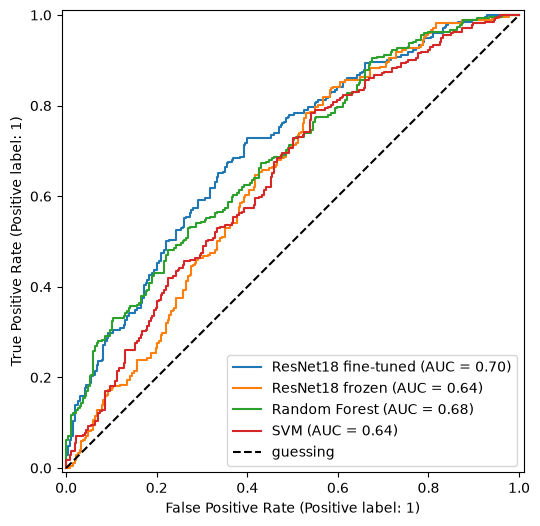

In [13]:
from sklearn.metrics import RocCurveDisplay

all_p = {
    "ResNet18 fine-tuned": dl_test.p_finetuned.values,
    "ResNet18 frozen": dl_test.p_frozen.values,
    "Random Forest": test_probs["Random Forest"],
    "SVM": test_probs["SVM"],
}

fig, ax = plt.subplots(figsize=(6, 6))
for name, p in all_p.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="guessing")
ax.legend()
plt.savefig("roc_all_models.png", dpi=150, bbox_inches="tight")
plt.show()

The fine-tuned ResNet18 curve is a little higher than the others for most of the range, but the curves are close and cross each other.

### 6.3 Is the difference real?
The test set is small, so the AUC could change a lot with different images. I repeat the test 500 times, each time picking patients at random with replacement, and look at the range of AUC values. I pick whole patients because one patient has several similar images.

In [14]:
test_df = df[df.split == "test"].reset_index(drop=True)
groups = test_df.groupby("patient").indices          # patient -> row numbers of their images
patients = list(groups)
rng = np.random.default_rng(SEED)

aucs = {name: [] for name in all_p}
for _ in range(500):
    chosen = rng.choice(len(patients), len(patients))                       # pick patients with replacement
    rows = np.concatenate([groups[patients[i]] for i in chosen])
    for name, p in all_p.items():
        aucs[name].append(roc_auc_score(y_test[rows], p[rows]))

for name, p in all_p.items():
    low, high = np.percentile(aucs[name], [2.5, 97.5])
    print(f"{name}: AUC {roc_auc_score(y_test, p):.3f} (95% range {low:.2f} to {high:.2f})")

ResNet18 fine-tuned: AUC 0.703 (95% range 0.63 to 0.77)
ResNet18 frozen: AUC 0.640 (95% range 0.57 to 0.71)
Random Forest: AUC 0.682 (95% range 0.59 to 0.76)
SVM: AUC 0.642 (95% range 0.55 to 0.72)


The 95% ranges overlap a lot (for example 0.63 to 0.77 for fine-tuned ResNet18 and 0.59 to 0.76 for Random Forest). So with this test set I can't say one model is clearly better. What I can say is that all of them are above guessing.

### 6.4 What does the Random Forest use?
Which features the forest relied on most.

In [15]:
importance = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
importance.head(8).round(3)

mean     0.074
p50      0.062
lbp_7    0.061
lbp_0    0.061
lbp_9    0.058
lbp_1    0.057
p10      0.052
lbp_4    0.051
dtype: float64

The Random Forest uses many features about equally. Brightness features (mean, median, 10th percentile) are at the top, but this could be tissue density or just scanner differences, so I can't say what it means medically.

### My General Perspective
Overall conclusion: the models are modest (AUC 0.64 to 0.70), deep learning is slightly ahead but not clearly, and none are usable clinically. We carry the fine-tuned ResNet18 at cut-off 0.43 into the Flask demo for project presentation, since it has the best nominal AUC and recall of 0.81.